# Sentiment dataset: Clustering


In [19]:
import sys
from pathlib import Path

# Find the project folder
project_dir = Path.cwd()
if not (project_dir / "utils").is_dir():
    project_dir = project_dir.parent
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from clustering import KMeans
from utils.data import load_train
from utils.preprocessing import make_preprocessor
from utils.evaluation import get_cluster_table, cluster_purity

x, y = load_train("sentiment")
print("Examples:", x.shape[0], " Features:", x.shape[1])


Examples: 12000  Features: 768


## Settings

Number of clusters, starting attempts, maximum iterations, and preprocessing. Seed 42 keeps runs repeatable. We use all 12,000 examples.


In [8]:
n_clusters = 3
n_init = 10
max_iters = 100
preprocessing = "none"
seed = 42

## K-means

Grouping similar examples around their nearest center, without using sentiment labels.


In [ ]:
# Keep preprocessing unsupervised: no sentiment labels are passed
allowed_preprocessing = ["none", "standard", "l2", "standard_l2", "minmax"]
if preprocessing not in allowed_preprocessing:
    raise ValueError("Choose one of the preprocessing methods listed above")

prep = make_preprocessor(preprocessing)
features = prep.fit_transform(x)

model = KMeans(n_clusters=n_clusters, max_iters=max_iters, n_init=n_init, seed=seed)
clusters = model.fit_predict(features)

print("Clusters:", n_clusters, " Preprocessing:", preprocessing)
print("Iterations in the selected run:", model.iterations)


## Cluster composition

The actual sentiment counts in each group, checked after clustering. Cluster numbers do not represent sentiment labels.


In [5]:
counts = get_cluster_table(y, clusters)
counts = counts.reindex(columns=[0, 1, 2], fill_value=0)
counts.columns = ["Negative", "Neutral", "Positive"]

cluster_table = counts.copy()
cluster_table["Total"] = cluster_table.sum(axis=1)
display(cluster_table)
print("Total examples:", int(cluster_table["Total"].sum()))


,Negative,Neutral,Positive,Total
Cluster,,,,
0,1431,1040,1367,3838
1,1201,1474,1809,4484
2,1368,1486,824,3678


Total examples: 12000


## Cluster plot

The size of each cluster and its mix of Negative, Neutral, and Positive examples.


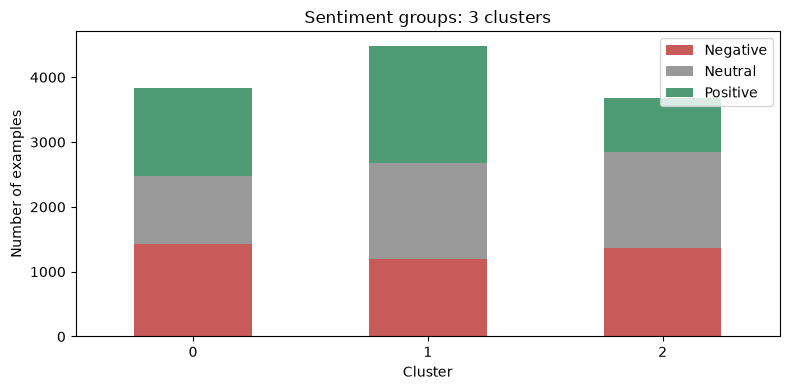

In [6]:
ax = counts.plot(
    kind="bar", stacked=True, figsize=(8, 4),
    color=["#c95a5a", "#999999", "#4f9b76"], rot=0
)
ax.set_xlabel("Cluster")
ax.set_ylabel("Number of examples")
ax.set_title(f"Sentiment groups: {n_clusters} clusters")
plt.tight_layout()
plt.show()


## Number of clusters

Compare different clusters. Only the number of buckets changes: the features, preprocessing, starting attempts, iteration limit, and seed stay the same.

The tables show which sentiments appear together in each run. Cluster IDs are just group numbers and do not have the same meaning between runs.


In [16]:
cluster_counts = [3, 5, 10,15,20,25,30]
rows = []

print(f"Preprocessing: {preprocessing}, starting attempts: {n_init}, seed: {seed}")

for count in cluster_counts:
    print(f"\nNumber of clusters: {count}", flush=True)
    comparison_model = KMeans(
        n_clusters=count, max_iters=max_iters, n_init=n_init, seed=seed
    )
    comparison_clusters = comparison_model.fit_predict(features)

    # Look at the sentiment labels only after forming the groups
    comparison_counts = get_cluster_table(y, comparison_clusters)
    comparison_counts = comparison_counts.reindex(columns=[0, 1, 2], fill_value=0)
    comparison_counts.columns = ["Negative", "Neutral", "Positive"]

    # Count the examples and show the sentiment mix inside each bucket
    composition = comparison_counts.copy()
    composition["Total"] = composition.sum(axis=1)
    display(composition)

    percentages = comparison_counts.div(comparison_counts.sum(axis=1), axis=0) * 100
    print("Sentiment percentages within each cluster:")
    display(percentages.round(2))

    rows.append({
        "clusters": count,
        "purity_percent": cluster_purity(y, comparison_clusters) * 100,
        "total_squared_distance": comparison_model.inertia,
    })

cluster_results = pd.DataFrame(rows)
print("\nComparison:")
display(cluster_results.round(2))


Preprocessing: none, starting attempts: 10, seed: 42

Number of clusters: 3


,Negative,Neutral,Positive,Total
Cluster,,,,
0,1386,1697,2065,5148
1,383,748,447,1578
2,2231,1555,1488,5274


Sentiment percentages within each cluster:


,Negative,Neutral,Positive
Cluster,,,
0,26.92,32.96,40.11
1,24.27,47.40,28.33
2,42.30,29.48,28.21



Number of clusters: 5


,Negative,Neutral,Positive,Total
Cluster,,,,
0,1109,775,1066,2950
1,506,740,1090,2336
2,308,650,406,1364
3,1121,771,346,2238
4,956,1064,1092,3112


... (20 outputs left out)

Sentiment percentages within each cluster:


,Negative,Neutral,Positive
Cluster,,,
0,36.98,27.69,35.33
1,23.65,42.81,33.53
2,54.20,32.77,13.03
3,43.79,28.92,27.29
4,5.93,45.26,48.81
5,17.81,32.45,49.74
6,61.65,32.33,6.02
7,70.33,23.73,5.93
8,43.29,20.84,35.87



Comparison:


,clusters,purity_percent,total_squared_distance
0,3,42.03,315418.86
1,5,42.18,303965.95
2,10,45.47,288688.89
3,15,46.92,280135.15
4,20,46.80,274112.53
5,25,46.85,270193.93
6,30,47.43,266599.17


## Effect of changing the number of clusters

The left graph shows how close examples are to their cluster centers. Smaller total squared distance means more compact buckets, and this usually decreases as we add clusters.

The right graph shows how closely the buckets match the sentiment labels. Purity is the share of examples matching their bucket's most common sentiment. 


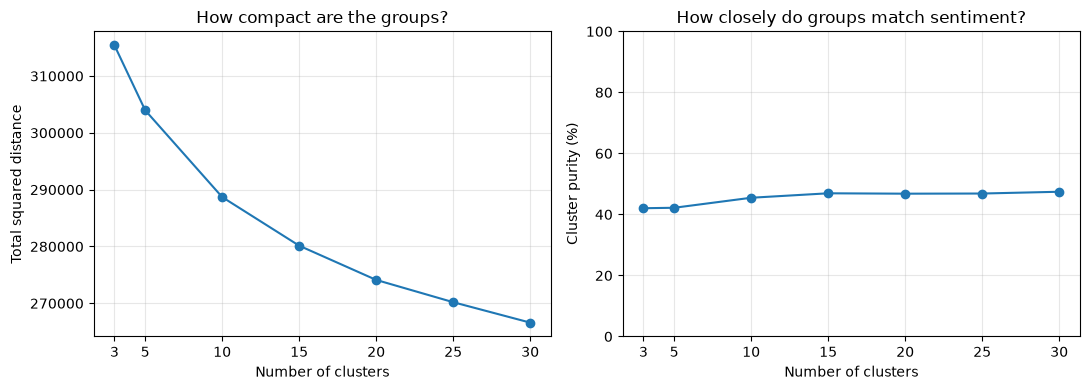

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    cluster_results["clusters"], cluster_results["total_squared_distance"], marker="o"
)
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Total squared distance")
axes[0].set_title("How compact are the groups?")

axes[1].plot(
    cluster_results["clusters"], cluster_results["purity_percent"], marker="o"
)
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Cluster purity (%)")
axes[1].set_ylim(0, 100)
axes[1].set_title("How closely do groups match sentiment?")

for ax in axes:
    ax.set_xticks(cluster_counts)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()
